In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 

from statsmodels.graphics.tsaplots import acf, pacf, plot_acf, plot_pacf
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn import metrics

from scikeras.wrappers import KerasRegressor
from keras.models import Sequential
from keras.layers import Dense, Dropout,LSTM
from keras.callbacks import EarlyStopping


import warnings
warnings.filterwarnings("ignore")

In [2]:
features_df = pd.read_csv("../data/Features_dataset.csv")
features_df.head()

,Store,Date,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,IsHoliday
0,1,05/02/2010,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,False
1,1,12/02/2010,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,True
2,1,19/02/2010,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,False
3,1,26/02/2010,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,False
4,1,05/03/2010,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,False


In [3]:
stores_df = pd.read_csv("../data/Stores_dataset.csv")
stores_df.head()

,Store,Type,Size
0,1,A,151315
1,2,A,202307
2,3,B,37392
3,4,A,205863
4,5,B,34875


In [4]:
sales_df = pd.read_csv("../data/Sales_dataset.csv")
sales_df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday
0,1,1,05/02/2010,24924.50,False
1,1,1,12/02/2010,46039.49,True
2,1,1,19/02/2010,41595.55,False
3,1,1,26/02/2010,19403.54,False
4,1,1,05/03/2010,21827.90,False


# Data Pre-Preparation

In [5]:
df = features_df.merge(stores_df, on="Store")
df = sales_df.merge(df, on=["Store", "Date", "IsHoliday"])
df.head()

,Store,Dept,Date,Weekly_Sales,IsHoliday,Temperature,Fuel_Price,MarkDown1,MarkDown2,MarkDown3,MarkDown4,MarkDown5,CPI,Unemployment,Type,Size
0,1,1,05/02/2010,24924.50,False,42.31,2.572,NaN,NaN,NaN,NaN,NaN,211.096358,8.106,A,151315
1,1,1,12/02/2010,46039.49,True,38.51,2.548,NaN,NaN,NaN,NaN,NaN,211.242170,8.106,A,151315
2,1,1,19/02/2010,41595.55,False,39.93,2.514,NaN,NaN,NaN,NaN,NaN,211.289143,8.106,A,151315
3,1,1,26/02/2010,19403.54,False,46.63,2.561,NaN,NaN,NaN,NaN,NaN,211.319643,8.106,A,151315
4,1,1,05/03/2010,21827.90,False,46.50,2.625,NaN,NaN,NaN,NaN,NaN,211.350143,8.106,A,151315


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Store         421570 non-null  int64  
 1   Dept          421570 non-null  int64  
 2   Date          421570 non-null  str    
 3   Weekly_Sales  421570 non-null  float64
 4   IsHoliday     421570 non-null  bool   
 5   Temperature   421570 non-null  float64
 6   Fuel_Price    421570 non-null  float64
 7   MarkDown1     150681 non-null  float64
 8   MarkDown2     111248 non-null  float64
 9   MarkDown3     137091 non-null  float64
 10  MarkDown4     134967 non-null  float64
 11  MarkDown5     151432 non-null  float64
 12  CPI           421570 non-null  float64
 13  Unemployment  421570 non-null  float64
 14  Type          421570 non-null  str    
 15  Size          421570 non-null  int64  
dtypes: bool(1), float64(10), int64(3), str(2)
memory usage: 48.6 MB


In [7]:
df = df.fillna(0)

In [8]:
df["Date"] = pd.to_datetime(df["Date"], format="%d/%m/%Y")
df["Type"] = df["Type"].astype("category")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 421570 entries, 0 to 421569
Data columns (total 16 columns):
 #   Column        Non-Null Count   Dtype         
---  ------        --------------   -----         
 0   Store         421570 non-null  int64         
 1   Dept          421570 non-null  int64         
 2   Date          421570 non-null  datetime64[us]
 3   Weekly_Sales  421570 non-null  float64       
 4   IsHoliday     421570 non-null  bool          
 5   Temperature   421570 non-null  float64       
 6   Fuel_Price    421570 non-null  float64       
 7   MarkDown1     421570 non-null  float64       
 8   MarkDown2     421570 non-null  float64       
 9   MarkDown3     421570 non-null  float64       
 10  MarkDown4     421570 non-null  float64       
 11  MarkDown5     421570 non-null  float64       
 12  CPI           421570 non-null  float64       
 13  Unemployment  421570 non-null  float64       
 14  Type          421570 non-null  category      
 15  Size          421570 non-nul

In [11]:
df.groupby(["Store", "Dept", "Date"]).sum(numeric_only=True)

Weekly_Sales  IsHoliday  Temperature  Fuel_Price  \
Store Dept Date                                                           
1     1    2010-02-05      24924.50          0        42.31       2.572   
           2010-02-12      46039.49          1        38.51       2.548   
           2010-02-19      41595.55          0        39.93       2.514   
           2010-02-26      19403.54          0        46.63       2.561   
           2010-03-05      21827.90          0        46.50       2.625   
...                             ...        ...          ...         ...   
45    98   2012-09-28        508.37          0        64.88       3.997   
           2012-10-05        628.10          0        64.89       3.985   
           2012-10-12       1061.02          0        54.47       4.000   
           2012-10-19        760.01          0        56.47       3.969   
           2012-10-26       1076.80          0        58.85       3.882   

                       MarkDown1  MarkDown2  MarkDown3  MarkDown4  MarkDown5  \
Store Dept Date                                                                
1     1    2010-02-05       0.00       0.00       0.00       0.00       0.00   
           2010-02-12       0.00       0.00       0.00       0.00       0.00   
           2010-02-19       0.00       0.00       0.00       0.00       0.00   
           2010-02-26       0.00       0.00       0.00       0.00       0.00   
           2010-03-05       0.00       0.00       0.00       0.00       0.00   
...                          ...        ...        ...        ...        ...   
45    98   2012-09-28    4556.61      20.64       1.50    1601.01    3288.25   
           2012-10-05    5046.74       0.00      18.82    2253.43    2340.01   
           2012-10-12    1956.28       0.00       7.89     599.32    3990.54   
           2012-10-19    2004.02       0.00       3.18     437.73    1537.49   
           2012-10-26    4018.91      58.08     100.00     211.94     858.33   

                              CPI  Unemployment    Size  
Store Dept Date                                          
1     1    2010-02-05  211.096358         8.106  151315  
           2010-02-12  211.242170         8.106  151315  
           2010-02-19  211.289143         8.106  151315  
           2010-02-26  211.319643         8.106  151315  
           2010-03-05  211.350143         8.106  151315  
...                           ...           ...     ...  
45    98   2012-09-28  192.013558         8.684  118221  
           2012-10-05  192.170412         8.667  118221  
           2012-10-12  192.327265         8.667  118221  
           2012-10-19  192.330854         8.667  118221  
           2012-10-26  192.308899         8.667  118221  

[421570 rows x 12 columns]

In [12]:
df[['Store', 'Dept']].value_counts()

Store  Dept
1      1       143
       2       143
       3       143
       4       143
       5       143
              ... 
38     35        1
       99        1
42     34        1
43     55        1
44     34        1
Name: count, Length: 3331, dtype: int64

In [13]:
st = 24
dt = 50

In [14]:
df_d = df[np.logical_and(df['Store'] == st, df['Dept'] == dt)]

## Predict the department-wide sales

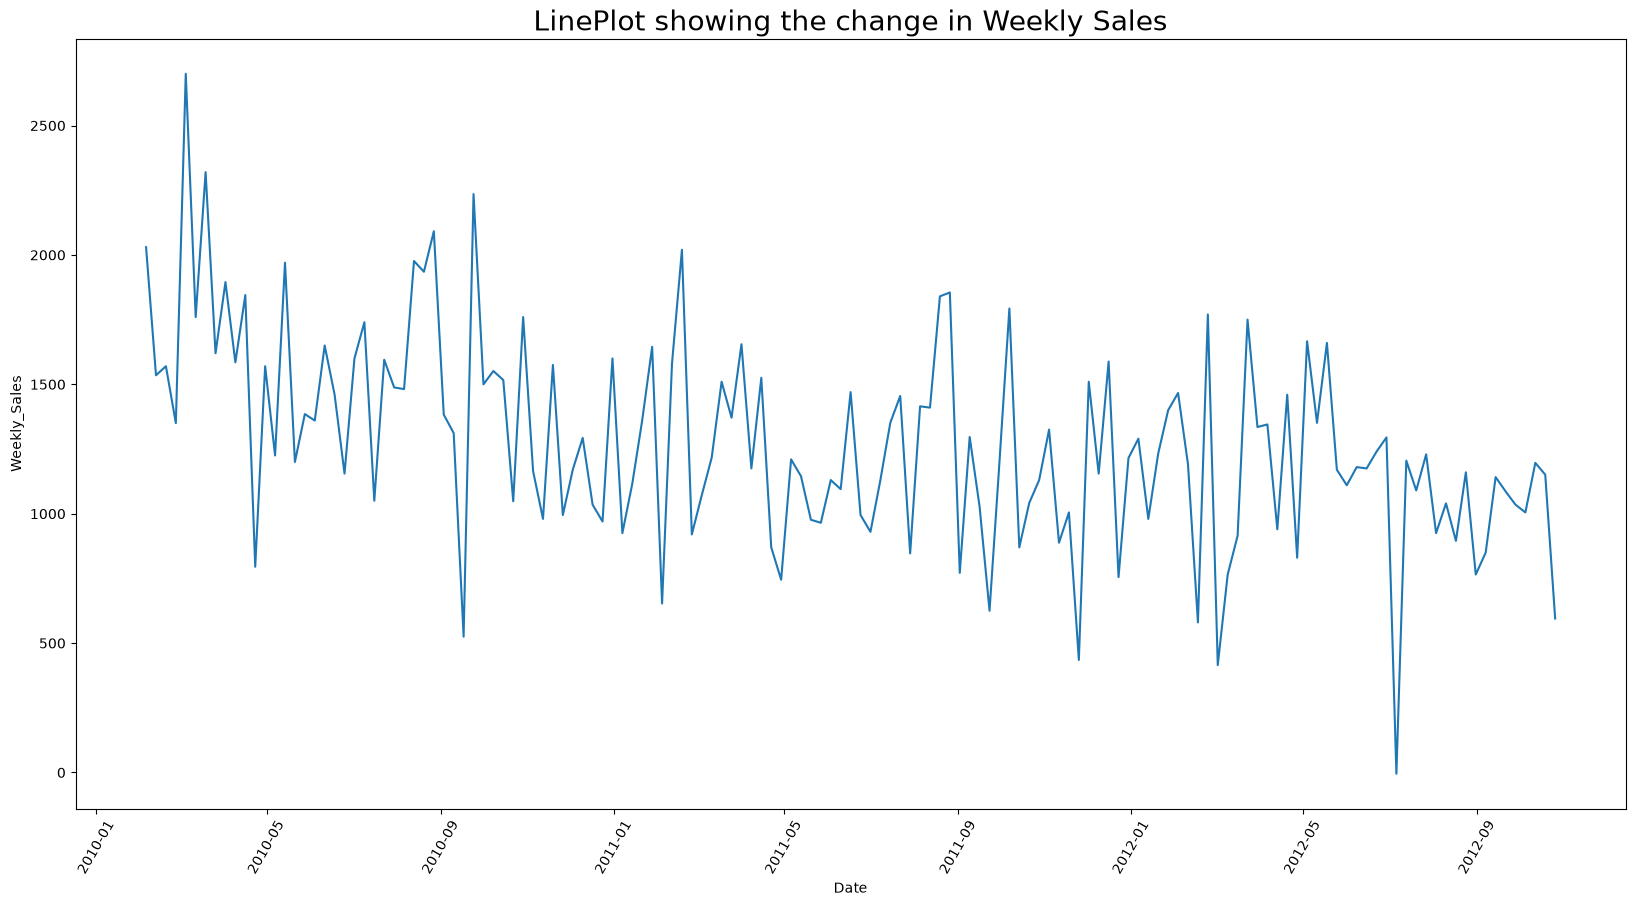

In [16]:
plt.figure
_ = plt.subplots(figsize = (20,10))
_ = plt.xticks(rotation = 60)
_ = sns.lineplot(data = df_d, x = 'Date', y = 'Weekly_Sales')
_ = plt.title('LinePlot showing the change in Weekly Sales', fontsize = 20)
plt.show()

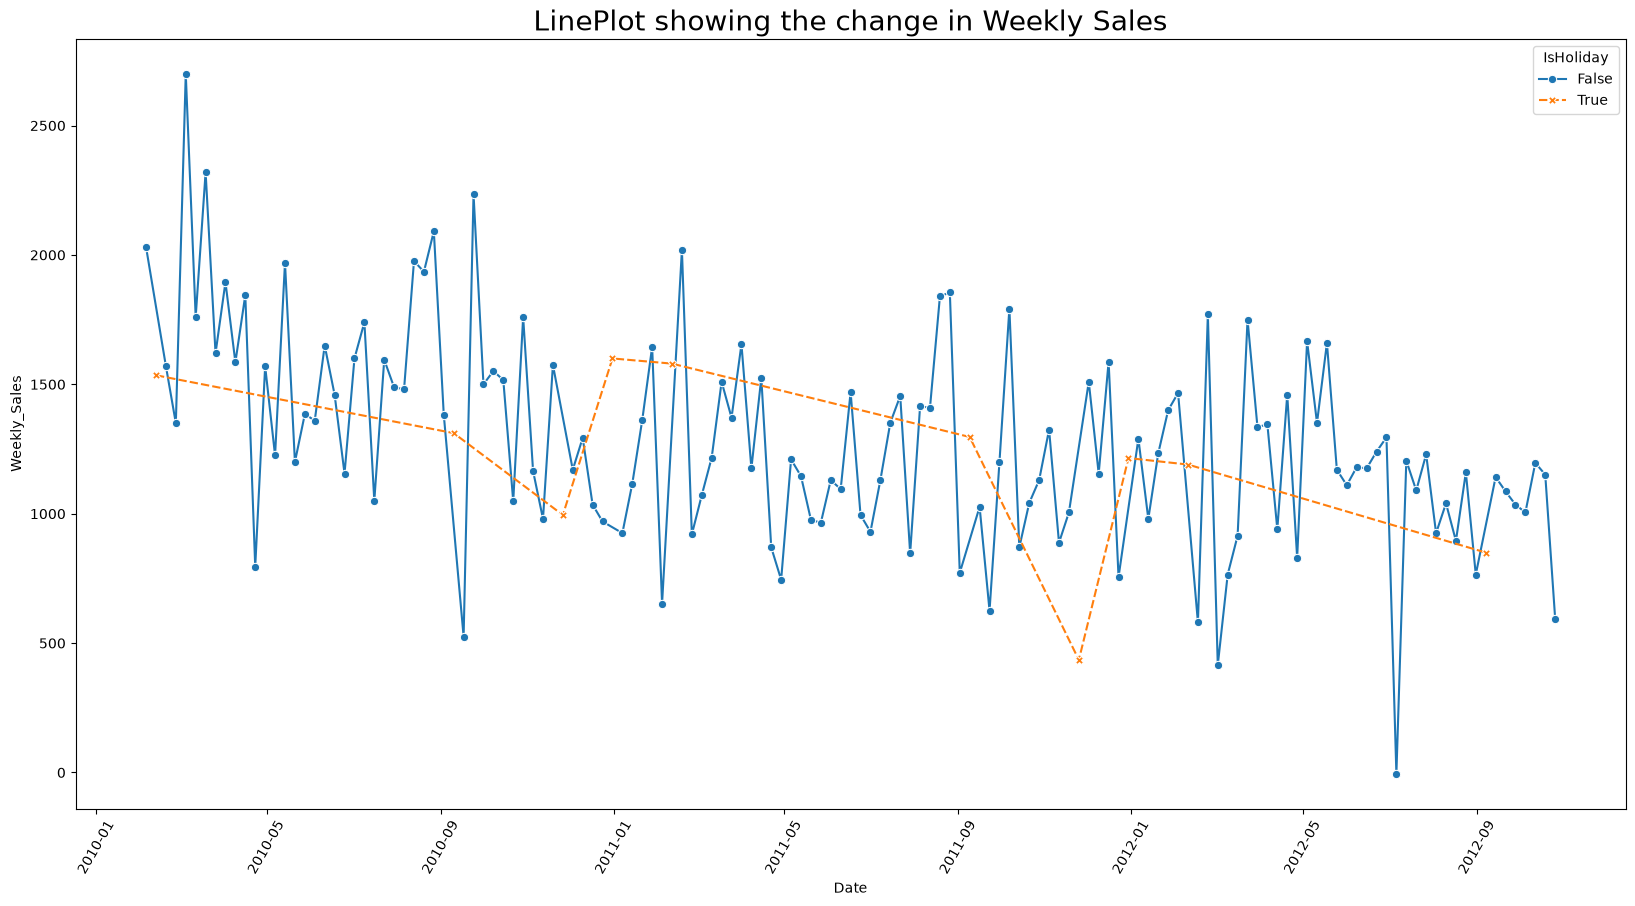

In [18]:
plt.figure
_ = plt.subplots(figsize = (20, 10))
_ = plt.xticks(rotation = 60)
_ = sns.lineplot(data = df_d, x = 'Date', y = 'Weekly_Sales', hue = 'IsHoliday', style = 'IsHoliday', markers = True, ci = 68)
_ = plt.title('LinePlot showing the change in Weekly Sales', fontsize=20)
plt.show()

In [20]:
time_series = df_d[['Date', 'Weekly_Sales']]
time_series = time_series.set_index('Date')
time_series = time_series['Weekly_Sales']
time_series

Date
2010-02-05    2030.0
2010-02-12    1535.0
2010-02-19    1570.0
2010-02-26    1350.0
2010-03-05    2700.0
               ...  
2012-09-28    1035.0
2012-10-05    1005.0
2012-10-12    1196.5
2012-10-19    1151.0
2012-10-26     595.0
Name: Weekly_Sales, Length: 143, dtype: float64

0     1.000000
1     0.130103
2     0.263880
3     0.136014
4     0.311210
5     0.126184
6     0.245963
7     0.088694
8     0.253053
9     0.071838
10    0.154257
Name: Correlation Coeff, dtype: float64
0     1.000000
1     0.131019
2     0.254831
3     0.086411
4     0.254782
5     0.043069
6     0.131390
7    -0.013168
8     0.127694
9    -0.028223
10    0.000674
Name: Partial Correlation Coeff, dtype: float64


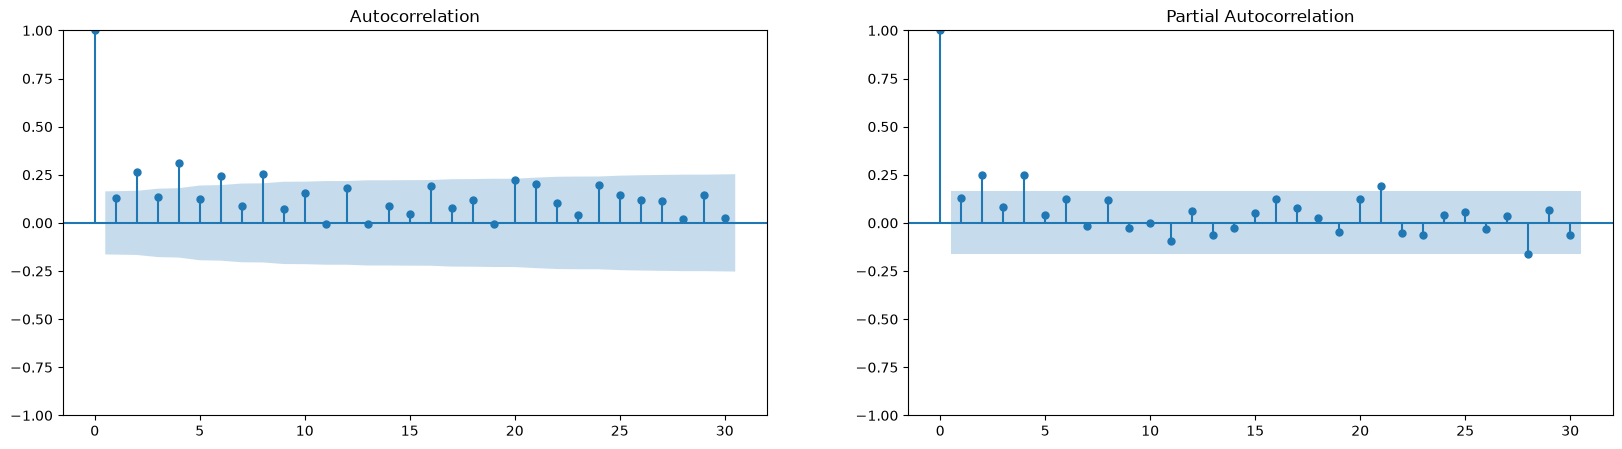

In [21]:
print(pd.Series(acf(time_series,nlags=10), name = "Correlation Coeff"))
print(pd.Series(pacf(time_series,nlags=10), name = "Partial Correlation Coeff"))


fig, axes = plt.subplots(1,2, figsize=(20,5))
_ = plot_acf(time_series, lags=30, ax=axes[0])
_ = plot_pacf(time_series, lags=30, ax=axes[1])

In [22]:
def series_to_supervised(in_data, tar_data, n_in=1, dropnan=True, target_dep=False):
    """
    Transformation into a training sample taking into account the lag
     : param in_data: Input fields
     : param tar_data: Output field (single)
     : param n_in: Lag shift
     : param dropnan: Do destroy empty lines
     : param target_dep: Whether to take into account the lag of the input field If taken into account, the input will start with lag 1
     : return: Training sample. The last field is the source
    """

    n_vars = in_data.shape[1]
    cols, names = list(), list()

    if target_dep:
        i_start = 1
    else:
        i_start = 0
    for i in range(i_start, n_in + 1):
        cols.append(in_data.shift(i))
        names += [('%s(t-%d)' % (in_data.columns[j], i)) for j in range(n_vars)]

    if target_dep:
        for i in range(n_in, -1, -1):
            cols.append(tar_data.shift(i))
            names += [('%s(t-%d)' % (tar_data.name, i))]
    else:
        # put it all together
        cols.append(tar_data)
        names.append(tar_data.name)
    agg = pd.concat(cols, axis=1)
    agg.columns = names

    # drop rows with NaN values
    if dropnan:
        agg.dropna(inplace=True)

    return agg

In [23]:
dataset = series_to_supervised(pd.DataFrame(time_series), time_series, 4)
dataset

,Weekly_Sales(t-0),Weekly_Sales(t-1),Weekly_Sales(t-2),Weekly_Sales(t-3),Weekly_Sales(t-4),Weekly_Sales
Date,,,,,,
2010-03-05,2700.0,1350.0,1570.0,1535.0,2030.0,2700.0
2010-03-12,1760.0,2700.0,1350.0,1570.0,1535.0,1760.0
2010-03-19,2320.0,1760.0,2700.0,1350.0,1570.0,2320.0
2010-03-26,1620.0,2320.0,1760.0,2700.0,1350.0,1620.0
2010-04-02,1895.0,1620.0,2320.0,1760.0,2700.0,1895.0
...,...,...,...,...,...,...
2012-09-28,1035.0,1086.5,1141.5,850.0,765.0,1035.0
2012-10-05,1005.0,1035.0,1086.5,1141.5,850.0,1005.0
2012-10-12,1196.5,1005.0,1035.0,1086.5,1141.5,1196.5


In [25]:
col = dataset.columns
X, Y = dataset[col[1:-1]], dataset[col[-1]]
print(f"Input: ${X.columns}")
print(f"Target: ${Y.name}")

Input: $Index(['Weekly_Sales(t-1)', 'Weekly_Sales(t-2)', 'Weekly_Sales(t-3)',
       'Weekly_Sales(t-4)'],
      dtype='str')
Target: $Weekly_Sales


## Data Normalization

In [26]:
scaler_x = MinMaxScaler(feature_range=(0,1))
scaler_y = MinMaxScaler(feature_range=(0,1))

scaled_x = scaler_x.fit_transform(X)
scaled_y = scaler_y.fit_transform(Y.values.reshape(-1,1))

In [27]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(scaled_x, scaled_y, test_size=0.3, shuffle=False)

In [28]:
res_train = scaler_y.inverse_transform(y_train).flatten()
res_test = scaler_y.inverse_transform(y_test).flatten()

## Linear Regression

In [29]:
regression = LinearRegression()

In [30]:
regression.fit(x_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 4)","[[0.05,0.17,0.08,0.24]]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[0.23]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](4,)","[1.81,1.46,1.28,1.28]"


In [31]:
y_pred_test_ln = regression.predict(x_test)
y_pred_test_ln = scaler_y.inverse_transform(y_pred_test_ln).flatten()

In [35]:
print(f"""
Correlation train: {regression.score(x_train, y_train)}
Correlation test: {regression.score(x_test, y_test)}
Mean Absoulte Error: {metrics.mean_absolute_error(y_test, y_pred_test_ln)}
Mean Squared Error: {metrics.mean_squared_error(y_test, y_pred_test_ln)}
Root Mean Squared Error: {np.sqrt(metrics.mean_squared_error(y_test, y_pred_test_ln))}
""")


Correlation train: 0.12826507500598916
Correlation test: -0.09385443205786403
Mean Absoulte Error: 1218.9282051415503
Mean Squared Error: 1496069.2012173075
Root Mean Squared Error: 1223.139076809055

